# Power consumption

A worked example of `quicksat`'s power consumption: what the sample satellite's equipment draws in each mode, and over the scenario sample's three orbits.

**Run all the cells.** The notebook reads `data/power_consumption.csv` and `data/scenario.yaml`, and works out the loads at each step of the run. Below are the power of each mode, the loads over the run by subsystem, and the energy per orbit.

For how each part works, such as the columns of the file, the margins and the slews, see `docs/power/power_consumption_ref.ipynb`.

In [1]:
# Change log. LAST_CHANGE and CHANGE_NOTE are typed in by hand. Update them whenever
# the inputs change, such as a piece of equipment added, a new power or a new mode, so that the figures below can be read
# against what produced them. The run time is recorded automatically, and says how
# stale the outputs stored in this notebook are relative to that last change.
from datetime import datetime

LAST_CHANGE = "2026-10-12"
CHANGE_NOTE = (
    "Sixteen rows of powered equipment from the sample satellite, with their "
    "power in idle, imaging, downlink and slew, and margins of 5 to 20%. The slew "
    "column holds the idle values for now."
)

print(f"last change  {LAST_CHANGE}")
print(f"             {CHANGE_NOTE}")
print(f"last run     {datetime.now().astimezone():%Y-%m-%d %H:%M %Z}")

last change  2026-10-12
             Sixteen rows of powered equipment from the sample satellite, with their power in idle, imaging, downlink and slew, and margins of 5 to 20%. The slew column holds the idle values for now.
last run     2026-10-12 22:42 CEST


In [2]:
import os
from pathlib import Path

import matplotlib.pyplot as plt

# Make the in-development quicksat package importable without installing it: walk up
# from the current directory to the repo root (the folder that holds the quicksat
# package) and switch to it. Works whether the notebook runs from sample/, the repo
# root, or the docs build.
here = Path.cwd()
repo_root = next(
    (p for p in (here, *here.parents) if (p / "quicksat" / "__init__.py").exists()),
    None,
)
if repo_root is None:
    raise RuntimeError("could not locate the quicksat repo root")
os.chdir(repo_root)

from quicksat.power.consumption import PowerConsumption, run_consumption
from quicksat.power.plots import consumption_plot
from quicksat.scenario.config import Scenario
from quicksat.scenario.run import run_scenario
from quicksat.utils.plot_helpers import STYLE

plt.style.use(STYLE)

## The consumption file

`power_consumption.csv` has one row for each piece of equipment that draws power. The structure, the insulation, the antennas and the other unpowered items of the mass budget's list are left out. A row gives how many units draw power, such as one of the two cold-redundant computers, the equipment margin, and the power of one unit in each mode.

The modes are the scenario's: `idle`, `imaging` and `downlink`, and `slew`, which the run gives the mode while the body turns. The `slew` column holds the idle values for now. Set it to what the satellite draws while it turns, such as more for the reaction wheels.

Each row's power, all its units together, without the margins:

In [3]:
DATA = Path("sample") / "power" / "data"
consumption = PowerConsumption.from_csv(DATA / "power_consumption.csv")
run = run_scenario(Scenario.from_yaml_file(DATA / "scenario.yaml"))
loads = run_consumption(consumption, run)

for note in loads.notes:
    print(note)
table = consumption.mode_table()
table.style.hide(axis="index").format(
    {column: "{:.0f}" for column in table.columns if column.endswith("[W]")}
)

equipment_id,equipment_name,subsystem,units_on,eqpt_margin [%],idle [W],imaging [W],downlink [W],slew [W]
obc,SSTL OBC750,OBDH,1,5.000000,10,10,10,10
star_tracker,Jena Astro HP optical head,ADCS,2,5.000000,12,12,12,12
reaction_wheel,Rockwell RSI 45,ADCS,4,5.000000,40,48,60,40
magnetorquer,ZARM MT30,ADCS,3,5.000000,3,3,3,3
imu,Northrop LN-200S,ADCS,1,5.000000,12,12,12,12
gps_receiver,RUAG PODRIX,ADCS,1,5.000000,10,10,10,10
pcdu,Airbus PCDU housekeeping,EPS,1,10.000000,15,15,15,15
sadm,Solar array drive,EPS,2,10.000000,8,2,8,8
s_band_rx,S-band transceiver receivers,COMM,2,5.000000,8,8,8,8
s_band_tx,S-band transceiver transmitter,COMM,1,5.000000,0,0,15,0


## The power of each mode

All the equipment together, without and with the equipment margins. The power budget adds the system margin on top.

In [4]:
consumption.mode_totals().style.format("{:.1f}")

,idle [W],imaging [W],downlink [W],slew [W]
without margins,188.0,290.0,293.0,188.0
with equipment margins,207.6,323.9,321.3,207.6


## The loads over the run

The loads against time, stacked by subsystem, with the equipment margins, and the eclipses shaded. The peaks are imaging and the downlink. The eclipse falls in nadir idle.

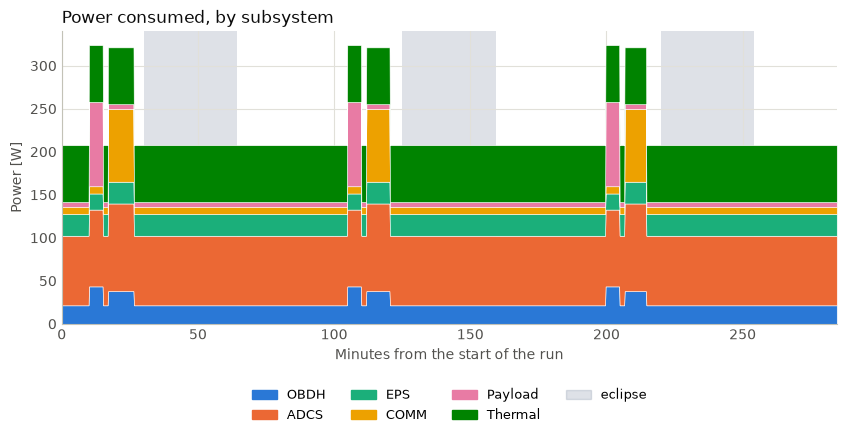

In [5]:
consumption_plot(loads)
plt.show()

## The loads per orbit

One row for each whole orbit, counted from the start of the run: the mean and the peak load, the energy drawn, and the part of it drawn in eclipse, which the battery must give.

In [6]:
loads.orbit_table.style.hide(axis="index").format(
    {
        "mean load [W]": "{:.1f}",
        "peak load [W]": "{:.1f}",
        "energy [Wh]": "{:.1f}",
        "in eclipse [Wh]": "{:.1f}",
    }
)

orbit,start [UTC],mean load [W],peak load [W],energy [Wh],in eclipse [Wh]
1,2026-10-01T09:00:00.000,225.0,323.9,355.7,118.7
2,2026-10-01T10:34:51.055,224.1,323.9,354.3,118.7
3,2026-10-01T12:09:42.109,223.2,323.9,352.9,118.7


## Changing the loads

Edit `sample/power/data/power_consumption.csv` and run the notebook again from the top. The notebook never writes it.

For example, give the reaction wheels 25 W a unit in `slew`, for the torque of the turns. Each slew then draws 60 W more than idle, with the margin on top.

Or add a mode, such as `safe`, as a column. It is noted as unused until an activity in the scenario has that mode.

The power budget, `power_budget.ipynb`, sets these loads against the generation and the battery.